# 01. EDA: разведочный анализ PAD-UFES-20

**Зачем этот ноутбук:** понять данные до обучения моделей (критерий 2, 12 баллов): источник, размер, структура,
классы, пропуски, ловушки, обоснование предобработки. Все графики сохраняются в `outputs/figures/eda_*.png`
и идут в отчёт и презентацию.

Перед запуском выполнены `src/prepare_images.py` и `src/make_splits.py`.

In [12]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

ROOT = Path("..").resolve()
sys.path.insert(0, str(ROOT / "src"))
from config import MALIGNANT

DATA = ROOT / "data" / "processed"
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

raw = pd.read_csv(DATA / "metadata.csv")              # все 2298 снимков (до удаления дубликатов)
df = pd.read_csv(DATA / "metadata_split.csv")         # после очистки + колонка split
removed = pd.read_csv(DATA / "removed_duplicates.csv")
raw["label"] = raw["diagnostic"].isin(MALIGNANT).astype(int)

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"eda_{name}.png", dpi=150)
    plt.show()

## 1. Размер и структура
Один пациент → несколько поражений → несколько фото. Поэтому делим по пациентам.

Снимков: 2298, пациентов: 1373, поражений (patient_id+lesion_id): 1891
Колонок: 29
Снимков на пациента: медиана 1, максимум 10


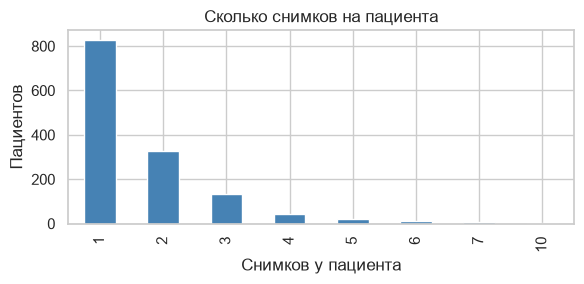

In [13]:
print(f"Снимков: {len(raw)}, пациентов: {raw.patient_id.nunique()}, "
      f"поражений (patient_id+lesion_id): {raw[['patient_id','lesion_id']].drop_duplicates().shape[0]}")
print(f"Колонок: {raw.shape[1]}")
per_patient = raw.groupby("patient_id").size()
print(f"Снимков на пациента: медиана {per_patient.median():.0f}, максимум {per_patient.max()}")

per_patient.value_counts().sort_index().plot.bar(figsize=(6, 3), color="steelblue")
plt.xlabel("Снимков у пациента"); plt.ylabel("Пациентов"); plt.title("Сколько снимков на пациента")
save("images_per_patient")

## 2. Классы
6 диагнозов: 3 рака (BCC, SCC, MEL) и 3 доброкачественных (ACK, NEV, SEK). Бинарная задача почти сбалансирована, а меланом очень мало (52), поэтому основная задача бинарная.

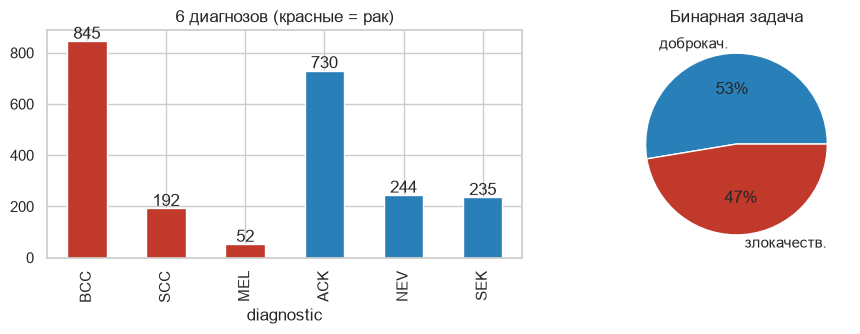

In [14]:
order = ["BCC", "SCC", "MEL", "ACK", "NEV", "SEK"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
counts = raw["diagnostic"].value_counts().reindex(order)
counts.plot.bar(ax=axes[0], color=["#c0392b"] * 3 + ["#2980b9"] * 3)
axes[0].set_title("6 диагнозов (красные = рак)")
for i, v in enumerate(counts):
    axes[0].text(i, v + 10, v, ha="center")
raw["label"].map({1: "злокачеств.", 0: "доброкач."}).value_counts().plot.pie(
    ax=axes[1], autopct="%1.0f%%", colors=["#2980b9", "#c0392b"])
axes[1].set_ylabel(""); axes[1].set_title("Бинарная задача")
save("classes")

## 3. Возраст и локализация

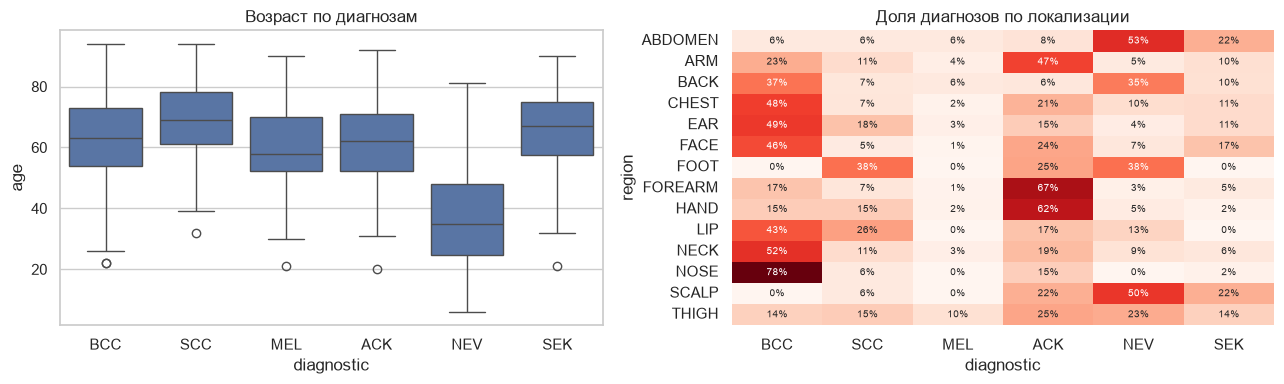

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=raw, x="diagnostic", y="age", order=order, ax=axes[0])
axes[0].set_title("Возраст по диагнозам")
ct = pd.crosstab(raw["region"], raw["diagnostic"], normalize="index")[order]
sns.heatmap(ct, annot=True, fmt=".0%", cmap="Reds", ax=axes[1], cbar=False, annot_kws={"size": 7})
axes[1].set_title("Доля диагнозов по локализации")
save("age_region")

## 4. Пропуски и ловушки утечки (важнейший раздел)
**Ловушка 1:** `biopsed` — все раки подтверждены биопсией → `biopsed=False` всегда означает доброкачественное.
**Ловушка 2:** у 804 снимков пусты 13 клинических полей, и **все они доброкачественные**.
**Ловушка 5:** `UNK` в `grew`/`changed` почти всегда означает рак.
Если подать это модели как есть, она выучит «правила сбора данных», а не медицину.

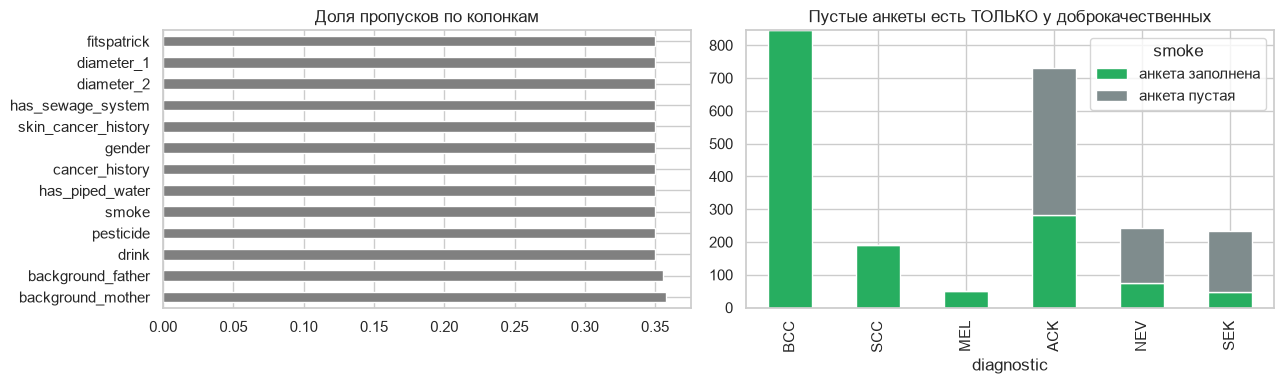

biopsed × диагноз:


biopsed,False,True
diagnostic,,
BCC,0,845
SCC,0,192
MEL,0,52
ACK,552,178
NEV,184,60
SEK,220,15


grew × диагноз:


grew,False,True,UNK
diagnostic,,,
BCC,150,429,266
SCC,40,77,75
MEL,4,37,11
ACK,590,134,6
NEV,71,137,36
SEK,116,111,8


In [16]:
miss = raw.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
miss.plot.barh(ax=axes[0], color="grey"); axes[0].set_title("Доля пропусков по колонкам")
pd.crosstab(raw["diagnostic"], raw["smoke"].isna().map({True: "анкета пустая", False: "анкета заполнена"})) \
    .reindex(order).plot.bar(ax=axes[1], stacked=True, color=["#27ae60", "#7f8c8d"])
axes[1].set_title("Пустые анкеты есть ТОЛЬКО у доброкачественных")
save("missing")
print("biopsed × диагноз:"); display(pd.crosstab(raw["diagnostic"], raw["biopsed"]).reindex(order))
print("grew × диагноз:"); display(pd.crosstab(raw["diagnostic"], raw["grew"]).reindex(order))

## 5. Тип кожи (Фитцпатрик): источник bias
Типы 5–6 почти отсутствуют → на тёмной коже модель не проверена.

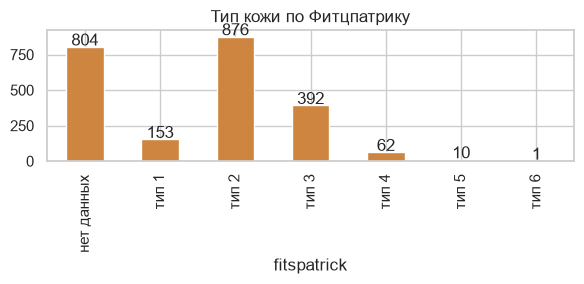

In [17]:
fz = raw["fitspatrick"].map(lambda v: "нет данных" if pd.isna(v) else f"тип {int(v)}").value_counts().sort_index()
fz.plot.bar(figsize=(6, 3), color="peru"); plt.title("Тип кожи по Фитцпатрику")
for i, v in enumerate(fz):
    plt.text(i, v + 10, v, ha="center")
save("fitzpatrick")

## 6. Симптомы и диагноз
Какой процент поражений каждого класса имеет симптом (по ответам «Да»/«Нет», без UNK).

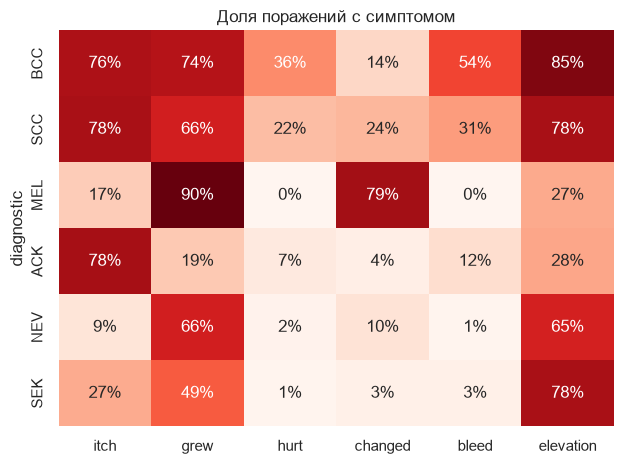

In [18]:
symptoms = ["itch", "grew", "hurt", "changed", "bleed", "elevation"]
rates = pd.DataFrame({s: raw[raw[s].isin(["True", "False"])].groupby("diagnostic")[s]
                      .apply(lambda x: (x == "True").mean()) for s in symptoms}).reindex(order)
sns.heatmap(rates, annot=True, fmt=".0%", cmap="Reds", cbar=False)
plt.title("Доля поражений с симптомом")
save("symptoms")

## 7. Примеры фото
Снимки со смартфона: разное освещение, масштаб, иногда маркер врача и линейка.

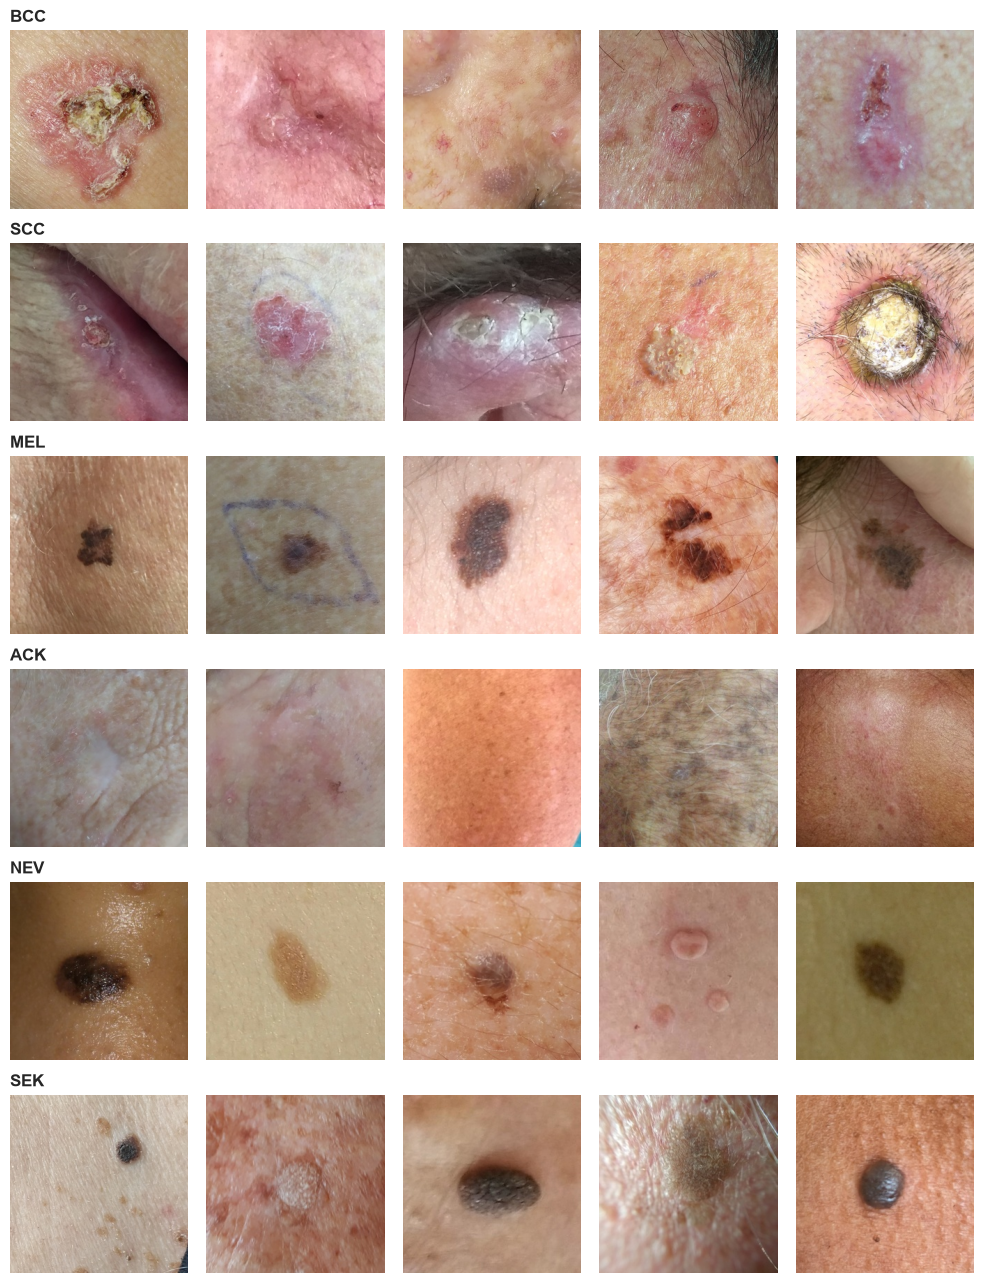

In [19]:
rng = np.random.default_rng(0)
fig, axes = plt.subplots(len(order), 5, figsize=(10, 13))
for r, d in enumerate(order):
    sample = df[df["diagnostic"] == d].sample(5, random_state=0)
    for c, f in enumerate(sample["img_file"]):
        axes[r, c].imshow(Image.open(DATA / "images_256" / f)); axes[r, c].axis("off")
    axes[r, 0].set_title(d, loc="left", fontweight="bold")
save("examples")

## 8. Исходные размеры фото
От ~200 до ~1800+ px → приводим к 256×256 (обоснование resize). Читает исходные архивы, около 1 минуты.

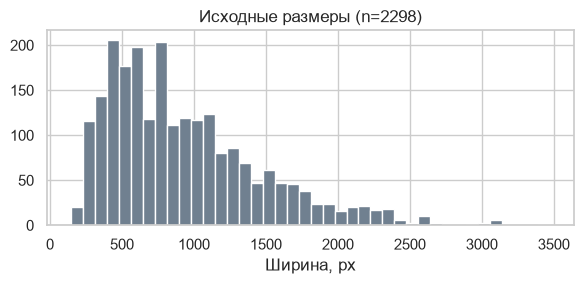

count    2298.0
mean      934.0
std       535.0
min       147.0
25%       528.0
50%       780.0
75%      1219.0
max      3474.0
dtype: float64


In [20]:
import zipfile
RAW_ZIPS = sorted((ROOT.parent / "zr7vgbcyr2-1" / "images").glob("imgs_part_*.zip"))
sizes = []
for zp in RAW_ZIPS:
    with zipfile.ZipFile(zp) as z:
        for n in z.namelist():
            if n.endswith(".png"):
                with z.open(n) as fh:
                    sizes.append(Image.open(fh).size[0])
if sizes:
    plt.figure(figsize=(6, 3)); plt.hist(sizes, bins=40, color="slategrey")
    plt.xlabel("Ширина, px"); plt.title(f"Исходные размеры (n={len(sizes)})")
    save("original_sizes")
    print(pd.Series(sizes).describe().round(0))

## 9. Дубликаты с конфликтом меток (ловушка 3)
Одно и то же фото подписано разными диагнозами → ошибка разметки (подтверждено авторами датасета,
см. Pedersen et al., 2025, arXiv:2504.11415). Удалено 27 снимков.

reason
conflicting_labels    24
exact_copy             3
Name: count, dtype: int64


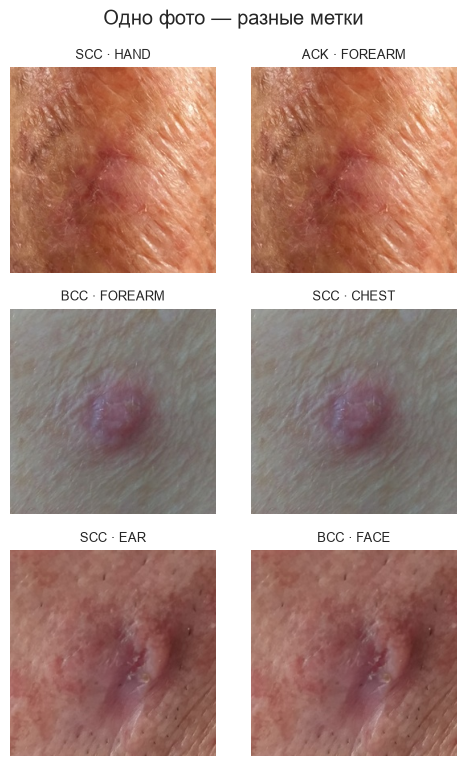

In [21]:
print(removed["reason"].value_counts())
pairs = raw[raw["md5"].isin(removed["md5"])].sort_values("md5")
show = [g for _, g in pairs.groupby("md5") if g["diagnostic"].nunique() > 1][:3]
fig, axes = plt.subplots(len(show), 2, figsize=(5, 2.6 * len(show)))
for r, g in enumerate(show):
    for c, (_, row) in enumerate(g.head(2).iterrows()):
        axes[r, c].imshow(Image.open(DATA / "images_256" / row["img_file"])); axes[r, c].axis("off")
        axes[r, c].set_title(f"{row['diagnostic']} · {row['region']}", fontsize=9)
plt.suptitle("Одно фото — разные метки")
save("duplicates")

## 10. Проверка деления train/val/test
Доли классов в частях похожи, пациенты не пересекаются.

In [22]:
display(pd.crosstab(df["diagnostic"], df["split"]).reindex(order))
display(df.groupby("split").agg(снимков=("img_id", "size"), пациентов=("patient_id", "nunique"),
                                доля_рака=("label", "mean")).round(3))
assert df.groupby("patient_id")["split"].nunique().max() == 1, "утечка пациентов!"
print("Пересечений пациентов между частями нет ✔")

split,test,train,val
diagnostic,,,
BCC,125,583,126
SCC,29,128,28
MEL,7,37,8
ACK,109,506,108
NEV,36,171,36
SEK,36,164,34


,снимков,пациентов,доля_рака
split,,,
test,342,207,0.471
train,1589,958,0.471
val,340,206,0.476


Пересечений пациентов между частями нет ✔


## Выводы EDA (перенести в отчёт)
1. Небольшой датасет: 2271 снимок после очистки, 1373 пациента → transfer learning + аугментация.
2. Бинарная задача сбалансирована (~47% рака); меланом всего 52 → 6-классовая задача только как бонус.
3. Найдено 5 ловушек: `biopsed`, пустые анкеты, дубликаты с конфликтом меток, неуникальный `lesion_id`, `UNK`.
   Решение: безопасные признаки, удаление дубликатов, деление по пациентам.
4. Тёмные типы кожи почти отсутствуют → ограничение и риск bias.
5. Фото разного размера и качества, встречаются маркеры врача → resize + проверка Grad-CAM.